Boundary (`rzout`) and limiter (`rzlim`) as stored in `geqdsk-ARCv3a`, read with TokaMaker's `read_eqdsk` through `helpers/parse_equil.py`. One boundary point is far from its neighbours; `find_boundary_points` takes the boundary's extrema, so that point sets the a, R, kappa and delta given to EPEDNN.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

ESCAPE_ROOT = Path.cwd().parent.parent.parent # ESCAPE root (examples/device_prediction/ARC/../../..)
sys.path.insert(0, str(ESCAPE_ROOT))
from helpers.parse_equil import mhd_load

mhd_fp = Path.cwd() / 'geqdsk-ARCv3a'
eq = mhd_load(None, 'eqdsk', str(mhd_fp)) # OpenFUSIONToolkit.TokaMaker.util.read_eqdsk
bdry, lim = eq['rzout'], eq['rzlim'] # (R, Z) in m

# A stray point is far from both of its neighbours on the boundary
STEP_FACTOR = 8 # stray if both steps exceed this times the median step
step = np.hypot(*np.diff(bdry, axis=0).T)
big = step > STEP_FACTOR * np.median(step)
stray = np.where(big[:-1] & big[1:])[0] + 1
print(f'{len(bdry)} boundary points, {len(lim)} limiter points')
print(f'Grid: R = {eq["rleft"]:.3f} to {eq["rleft"] + eq["rdim"]:.3f} m, Z = {eq["zmid"] - eq["zdim"] / 2:.3f} to {eq["zmid"] + eq["zdim"] / 2:.3f} m')
print(f'Limiter: R = {lim[:, 0].min():.3f} to {lim[:, 0].max():.3f} m, Z = {lim[:, 1].min():.3f} to {lim[:, 1].max():.3f} m')
print(f'Boundary: R = {bdry[:, 0].min():.3f} to {bdry[:, 0].max():.3f} m, Z = {bdry[:, 1].min():.3f} to {bdry[:, 1].max():.3f} m')
for i in stray:
    print(f'Stray boundary point {i}: R = {bdry[i, 0]:.6f} m, Z = {bdry[i, 1]:.6f} m')

102 boundary points, 33 limiter points
Grid: R = 0.100 to 7.000 m, Z = -5.500 to 5.500 m
Limiter: R = 3.420 to 5.820 m, Z = -4.090 to 4.090 m
Boundary: R = 2.685 to 5.803 m, Z = -5.655 to 2.198 m
Stray boundary point 89: R = 2.685470 m, Z = -5.655071 m


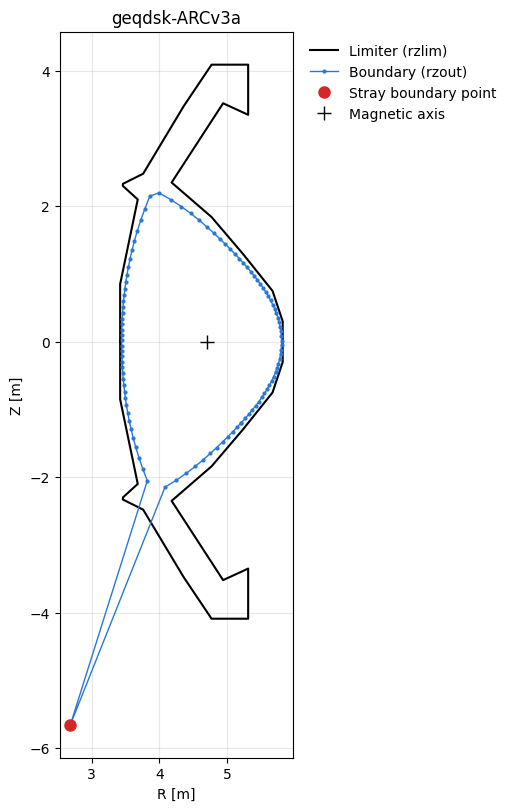

In [2]:
fig, ax = plt.subplots(figsize=(7, 8), layout='constrained')
ax.plot(*np.vstack([lim, lim[:1]]).T, color='k', lw=1.5, label='Limiter (rzlim)')
ax.plot(*bdry.T, '.-', color='#2a78d6', lw=1, ms=4, label='Boundary (rzout)')
ax.plot(*bdry[stray].T, 'o', color='#d62728', ms=8, label='Stray boundary point')
ax.plot(eq['raxis'], eq['zaxis'], '+', color='k', ms=10, label='Magnetic axis')
ax.set_aspect('equal')
ax.set_xlabel('R [m]')
ax.set_ylabel('Z [m]')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
ax.set_title(mhd_fp.name)
plt.show()

geqdsk-ARCv3a_fixedbdry: replaced ( 2.685469681E+00-5.655071464E+00) with ( 3.993119606E+00-2.197528340E+00)
Boundary: R = 3.441 to 5.803 m, Z = -2.198 to 2.198 m


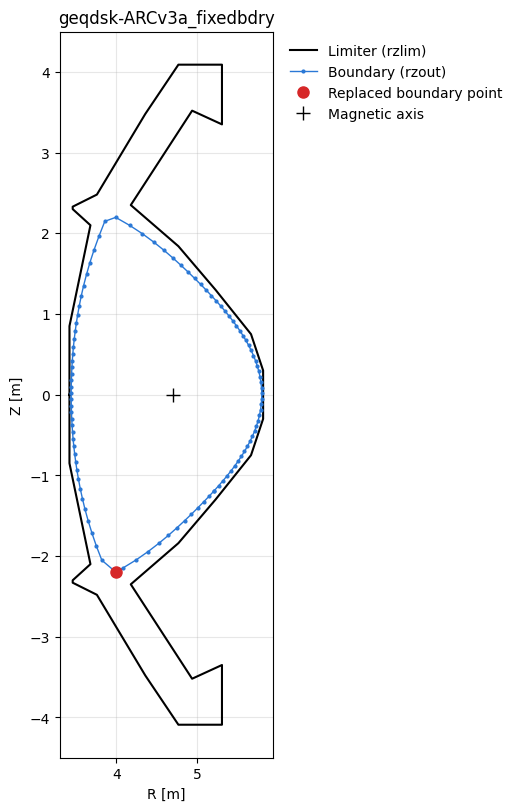

In [3]:
# Copy of the g-file with the stray point replaced. ARC is up-down symmetric, and the stray point sits
# where the lower X-point belongs, so use the mirror image of the upper X-point (the boundary's top)
assert len(stray) == 1
fixed_fp = mhd_fp.with_name(mhd_fp.name + '_fixedbdry')
R_top, Z_top = bdry[bdry[:, 1].argmax()]
old_txt = f'{bdry[stray[0], 0]:16.9E}{bdry[stray[0], 1]:16.9E}'
new_txt = f'{R_top:16.9E}{-Z_top:16.9E}'
txt = mhd_fp.read_text()
assert txt.count(old_txt) == 1
fixed_fp.write_text(txt.replace(old_txt, new_txt))
print(f'{fixed_fp.name}: replaced ({old_txt}) with ({new_txt})')

eq_fixed = mhd_load(None, 'eqdsk', str(fixed_fp))
bdry_fixed = eq_fixed['rzout']
print(f'Boundary: R = {bdry_fixed[:, 0].min():.3f} to {bdry_fixed[:, 0].max():.3f} m, Z = {bdry_fixed[:, 1].min():.3f} to {bdry_fixed[:, 1].max():.3f} m')

fig, ax = plt.subplots(figsize=(7, 8), layout='constrained')
ax.plot(*np.vstack([eq_fixed['rzlim'], eq_fixed['rzlim'][:1]]).T, color='k', lw=1.5, label='Limiter (rzlim)')
ax.plot(*bdry_fixed.T, '.-', color='#2a78d6', lw=1, ms=4, label='Boundary (rzout)')
ax.plot(*bdry_fixed[stray].T, 'o', color='#d62728', ms=8, label='Replaced boundary point')
ax.plot(eq_fixed['raxis'], eq_fixed['zaxis'], '+', color='k', ms=10, label='Magnetic axis')
ax.set_aspect('equal')
ax.set_xlabel('R [m]')
ax.set_ylabel('Z [m]')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
ax.set_title(fixed_fp.name)
plt.show()